In [9]:
import jax
import os

In [10]:
import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [11]:
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl

import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d

import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm, logm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt

In [12]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

In [13]:
duration_1qb * dt

49.77777777777777

# Calibrate

In [14]:
# Load shapes
fname_1qb = "../pico-pulses/saved-pulses-2024-02-16/a_single_qubit_gateset_R1e-5.csv"
pico_a = ps.from_csv(fname_1qb)
pico_a = np.vstack([pico_a, 1.0 * np.ones(pico_a.shape[1])])

names_1qb = ["X1", "X2", "SX1", "SX2", "ID1", "ID2"]
angles_1qb = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi, 0.2, 0.0]

In [15]:
cal_1qb_robust = ps.calibrate_gateset(
    gateset=pico_a,
    names=names_1qb,
    angles=angles_1qb,
    duration=duration_1qb,
    dt=dt,
)

Storing symbolic pulses...


Adjusting X1 by amplitude 0.20 for angle 1.50π
Adjusting X2 by amplitude 0.20 for angle 0.50π
Adjusting SX1 by amplitude 0.20 for angle 1.25π
Adjusting SX2 by amplitude 0.20 for angle 0.25π
Zero area signal. Adjusting ID1 by amplitude 0.20 (using provided angle).
Adjusting ID2 by amplitude 0.00 for angle 0.00π


In [16]:
cal_1qb_default = ps.default_single_qubit_gateset(
    names_1qb,
    duration_1qb,
    dt,
)

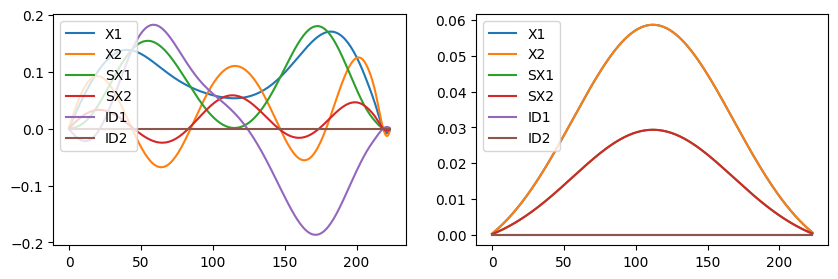

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

ax = axes[0]
for i, (k, v) in enumerate(cal_1qb_robust.items()):
    ax.plot(ps.get_samples(v).real, label=names_1qb[i])
ax.legend(loc="upper left")

ax = axes[1]
for i, (k, v) in enumerate(cal_1qb_default.items()):
    ax.plot(ps.get_samples(v).real, label=names_1qb[i])
ax.legend(loc="upper left")

In [18]:
# Load shapes
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"

base_2qb = {k: ps.from_csv(fname(k))[0] for k in ["default", "robust"]}
robust_2qb = 2 * [base_2qb["robust"]]
default_2qb = 2 * [base_2qb["default"]]
names_2qb = ["+", "-"]

In [19]:
cal_2qb_robust = ps.calibrate_gateset(
    gateset=robust_2qb,
    names=names_2qb,
    angles=[0.125 * np.pi, -0.125 * np.pi],
    duration=duration_2qb,
    dt=dt,
    samples=32,
)

Storing symbolic pulses...
Adjusting + by amplitude 0.30 for angle 0.12π
Adjusting - by amplitude-0.30 for angle-0.12π


In [20]:
cal_2qb_default = ps.calibrate_gateset(
    gateset=default_2qb,
    names=names_2qb,
    angles=[0.125 * np.pi, -0.125 * np.pi],
    duration=duration_2qb,
    dt=dt,
    samples=32,
)

Storing symbolic pulses...
Adjusting + by amplitude 0.30 for angle 0.12π
Adjusting - by amplitude-0.30 for angle-0.12π


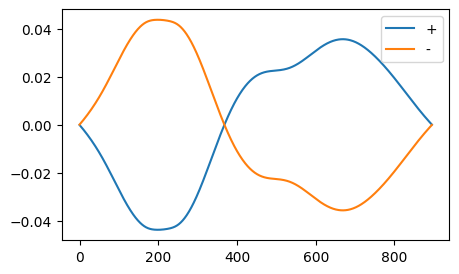

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
for i, (k, v) in enumerate(cal_2qb_robust.items()):
    ax.plot(ps.get_samples(v).real, label=names_2qb[i])
ax.legend(loc="upper right")

# Build circuit

In [22]:
registers = [0, 1]
coupling_map = ps.backend_edges(backend)

# We will simulate only 1 layer, then multiple unitaries to get all the layers
xy4_depth = 20 * 20

In [23]:
def prepare_state(circ, registers):
    # [circ.h(r) for r in registers]
    [circ.sx(r) for r in registers]

def apply_xy4(circ, q, reverse=False):
    if reverse:
        circ.y(q)
        circ.x(q)
        circ.y(q)
        circ.x(q)
    else:
        circ.x(q)
        circ.y(q)
        circ.x(q)
        circ.y(q)
    # circ.id(q)
    # circ.id(q)
    # circ.id(q)
    # circ.id(q)

def apply_simultaneous_xy4(circ, q0, q1):
    apply_xy4(circ, q0)
    apply_xy4(circ, q1, reverse=False)

In [24]:
prep_circ = qk.QuantumCircuit(2, 2)
run_circ = qk.QuantumCircuit(2, 2)

prepare_state(prep_circ, registers)
for _ in range(1):
    apply_simultaneous_xy4(run_circ, 0, 1)
# prepare_state(prep_circ, registers)

# circ.draw('mpl')

In [25]:
mb = ps.MomentBuilder(
    coupling_map=ps.backend_edges(backend),
)

prep_moments = mb.build_moments(
    prep_circ, 
    optimization_level=0, 
)

run_moments = mb.build_moments(
    run_circ, 
    optimization_level=0, 
)

In [26]:
prep_sched = ps.build_pulse_schedule(
    prep_moments,
    qubit_gates=cal_1qb_default,
    cr_gates=cal_2qb_default,
    registers=registers,
    backend=backend,
    name="default-hamiltonian-simulation",
    dt=dt,
    insert_identities=True,
    verbose=True
)

prep_robust_sched = ps.build_pulse_schedule(
    prep_moments,
    qubit_gates=cal_1qb_robust,
    cr_gates=cal_2qb_robust,
    registers=registers,
    backend=backend,
    name="robust-hamiltonian-simulation",
    dt=dt,
    insert_identities=True,
    verbose=False
)

Building schedule with 1 moments. 
	 Qubit gateset: dict_keys(['X1', 'X2', 'SX1', 'SX2', 'ID1', 'ID2'])
	 CR gateset: dict_keys(['+', '-'])
	 Registers: [0, 1]
	 Insert identities: True


In [27]:
run_sched = ps.build_pulse_schedule(
    run_moments,
    qubit_gates=cal_1qb_default,
    cr_gates=cal_2qb_default,
    registers=registers,
    backend=backend,
    name="default-hamiltonian-simulation",
    dt=dt,
    insert_identities=True,
    verbose=True
)

run_robust_sched = ps.build_pulse_schedule(
    run_moments,
    qubit_gates=cal_1qb_robust,
    cr_gates=cal_2qb_robust,
    registers=registers,
    backend=backend,
    name="robust-hamiltonian-simulation",
    dt=dt,
    insert_identities=True,
    verbose=False
)

Building schedule with 6 moments. 
	 Qubit gateset: dict_keys(['X1', 'X2', 'SX1', 'SX2', 'ID1', 'ID2'])
	 CR gateset: dict_keys(['+', '-'])
	 Registers: [0, 1]
	 Insert identities: True


/home/andy/Documents/Research/pulse-simulator/.venv/lib/python3.10/site-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


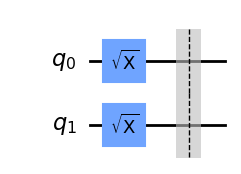

In [28]:
circ2 = ps.build_circuit(prep_moments, registers, insert_identities=False, barriers=True)
circ2.draw('mpl')

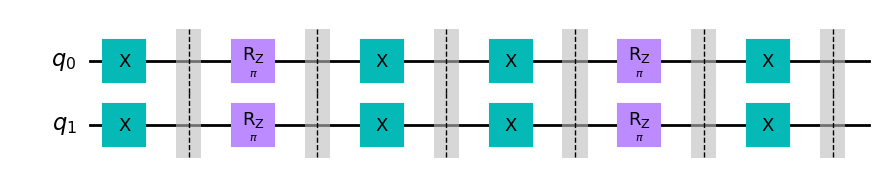

In [29]:
circ2 = ps.build_circuit(run_moments, registers, insert_identities=False, barriers=True)
circ2.draw('mpl')

# Solvers

In [78]:
cvars = ps.backend_simulation_vars(
    backend, rabi=False, units=1e9
)
for i,j in [(0,1), (1,2), (2,3), (3,4)]:
    cvars[f"jq{i}q{j}"] = cvars[f"jq{i}q{j}"] * 2

In [79]:
solver_r0 = ps.build_solver(
    registers,
    backend,
    include_crosstalk=False,
    simulation_vars=cvars,
    include_dissipation=False,
    simulation_dt=dt,
    verbose=True
)

solver_rx0 = ps.build_solver(
    registers,
    backend,
    include_crosstalk=True,
    include_dissipation=False,
    simulation_vars=cvars,
    simulation_dt=dt
)

solver_rx = ps.build_solver(
    registers,
    backend,
    include_crosstalk=True,
    include_dissipation=True,
    simulation_vars=cvars,
    simulation_dt=dt
)

Building fake_manila model...
	Timestep:  0.22
	Rabi: False
	Crosstalk: False
	Dissipation: False
	Edges: [(0, 1)]


In [66]:
cvars = ps.backend_simulation_vars(
    backend, rabi=False, units=1e9
)
# Mock up fine calibration issue
for i in range(5):
    prev = cvars[f"omegad{i}"]
    new =  prev * 0.975
    cvars[f"omegad{i}"] = new
    print(f"{2 * np.pi * new}, previously {2 * np.pi *prev}")

for i,j in [(0,1), (1,2), (2,3), (3,4)]:
    cvars[f"jq{i}q{j}"] = cvars[f"jq{i}q{j}"] * 2

solver_r0_calibrate = ps.build_solver(
    registers,
    backend,
    include_crosstalk=False,
    include_dissipation=False,
    simulation_dt=dt,
    simulation_vars=cvars,
    simulation_rabi=True,
    verbose=True
)

solver_rx0_calibrate = ps.build_solver(
    registers,
    backend,
    include_crosstalk=True,
    include_dissipation=False,
    simulation_vars=cvars,
    simulation_rabi=True,
    simulation_dt=dt
)

solver_rx_calibrate = ps.build_solver(
    registers,
    backend,
    include_crosstalk=True,
    include_dissipation=True,
    simulation_rabi=True,
    simulation_vars=cvars,
    simulation_dt=dt
)

0.9500000000000001, previously 1.0
0.9500000000000001, previously 1.0
0.9500000000000001, previously 1.0
0.9500000000000001, previously 1.0
0.9500000000000001, previously 1.0
Building fake_manila model...
	Timestep:  0.22
	Rabi: True
	Crosstalk: False
	Dissipation: False
	Edges: [(0, 1)]


In [67]:
# ps.build_model(
#     registers,
#     backend,
#     include_crosstalk=True,
#     include_dissipation=True,
#     simulation_rabi=True,
#     simulation_vars=cvars,
#     simulation_dt=dt
# )

Could increase crosstalk or mess with manual properties...

In [68]:
# model_args = ps.build_model(
#     registers,
#     backend,
#     include_crosstalk=True,
#     include_dissipation=False,
#     simulation_dt=dt
# )

# model_args['static_hamiltonian'] = 10 * model_args['static_hamiltonian']

# solver_rx0 = qk_d.Solver(**model_args)

# Runs

## Timesteps

In [69]:
# measure after each non-phase moment
prep_times = dt * np.cumsum(
    ps.durations_of_moments(prep_moments, duration_1qb, duration_2qb)
)

run_times = dt * np.cumsum(
    ps.durations_of_moments(run_moments, duration_1qb, duration_2qb)
)

# targets at measure times
prep_Uts = []
for i, m in enumerate(prep_moments):
    prep_Uts.append(ps.build_operator(prep_moments[0:i+1], registers))

run_Uts = []
for i, m in enumerate(run_moments):
    run_Uts.append(ps.build_operator(run_moments[0:i+1], registers))

# Target
# target = ps.build_operator(run_moments[:-1], registers)

In [70]:
prep_times

array([49.77777778])

In [71]:
def extend(
    prep_Uts, 
    prep_times, 
    run_Uts, 
    run_times, 
    xy4_depth
):
    Uts = []
    measure_times = []

    # Intial
    prefactor = prep_Uts[-1]
    pretime = prep_times[-1]
    Uts.append(prep_Uts[-1])
    measure_times.append(prep_times[-1])

    # DD layers
    for i in range(xy4_depth):
        for t, U in zip(run_times, run_Uts):
            Uts.append(U @ prefactor)
            measure_times.append(t + pretime)
        prefactor = run_Uts[-1] @ prefactor
        pretime = run_times[-1] + pretime

    # Final
    Uts.append(prep_Uts[-1] @ prefactor)
    measure_times.append(prep_times[-1] + pretime)
    
    return Uts, measure_times

In [72]:
Uts, measure_times = extend(
    prep_Uts, 
    prep_times, 
    run_Uts, 
    run_times, 
    xy4_depth
)

## Without decoherence

In [73]:
y0 = ps.qiskit_identity_operator(len(registers))
# y0 = ps.qiskit_ground_state(len(registers), open=False)

labels = ["robust",  "default"]
all_schedules = [prep_robust_sched, prep_sched]

# ==========

solver_rx0.model.evaluation_mode = "dense"
prep_res_x0 = solver_rx0.solve(
    t_span=[0.0, prep_sched.duration * dt],
    t_eval=prep_times,
    y0=y0,
    signals=all_schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(prep_moments, registers))
# y_target = y0.evolve(target)

for i, ell in enumerate(labels):
    print(f"\tInfidelity of {ell}: ", 1 - qk.quantum_info.process_fidelity(prep_res_x0[i].y[-1], target))

# for i, ell in enumerate(labels):
#     print(f"\tInfidelity of {ell} schedule: {1 - qk.quantum_info.state_fidelity(prep_res_x0[i].y[-1], y_target)}")

	Infidelity of robust:  1.8020446422628567e-05
	Infidelity of default:  0.008261116285627201


In [74]:
y0 = ps.qiskit_identity_operator(len(registers))
# y0 = ps.qiskit_ground_state(len(registers), open=False)

labels = ["robust",  "default"]
all_schedules = [run_robust_sched, run_sched]

# ==========

solver_rx0.model.evaluation_mode = "dense"
run_res_x0 = solver_rx0.solve(
    t_span=[0.0, run_sched.duration * dt],
    t_eval=run_times,
    y0=y0,
    signals=all_schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(run_moments, registers))
# y_target = y0.evolve(target)

for i, ell in enumerate(labels):
    print(f"\tInfidelity of {ell}: ", 1 - qk.quantum_info.process_fidelity(run_res_x0[i].y[-1], target))

# for i, ell in enumerate(labels):
#     print(f"\tInfidelity of {ell} schedule: {1 - qk.quantum_info.state_fidelity(run_res_x0[i].y[-1], y_target)}")

	Infidelity of robust:  8.502383367325894e-05
	Infidelity of default:  0.12436183396821654


In [75]:
Uts_0, measure_times_0 = extend(
    prep_res_x0[0].y, 
    prep_times, 
    run_res_x0[0].y, 
    run_times, 
    xy4_depth
)

Uts_1, measure_times_1 = extend(
    prep_res_x0[1].y, 
    prep_times, 
    run_res_x0[1].y, 
    run_times, 
    xy4_depth
)

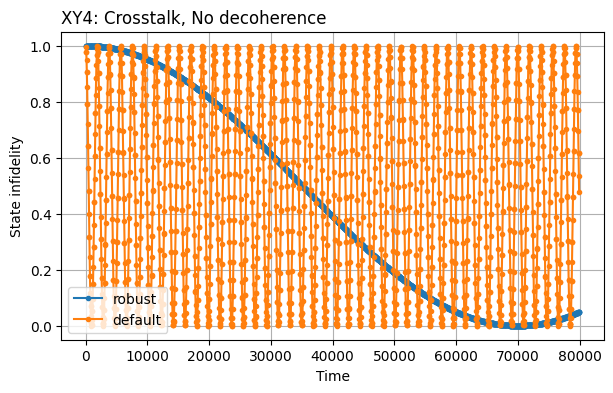

In [77]:
fig, axes = plt.subplots(1, figsize=[7, 4])
axes = axes if isinstance(axes, np.ndarray) else [axes]

y0 = ps.qiskit_ground_state(len(registers), open=False)

ax = axes[0]
ax.set_title("XY4: Crosstalk, No decoherence", loc='left')

for i, Uts_i in enumerate([Uts_0, Uts_1]):
    infids = []
    for r, t in zip(Uts_i, Uts):
        # infids.append(1 - qk.quantum_info.process_fidelity(r, t, require_cp=False, require_tp=False))
        infids.append(qk.quantum_info.state_fidelity(y0.evolve(r), y0.evolve(t), validate=False))
    ax.plot(measure_times, infids, label=labels[i], marker=".")

ax.set_xlabel("Time")
ax.legend(loc="lower left")
# ax.set_yscale("log")
ax.set_ylabel("State infidelity")
ax.grid(True)

## Without decoherence + Fine calibration issue

In [ ]:
y0 = ps.qiskit_identity_operator(len(registers))
# y0 = ps.qiskit_ground_state(len(registers), open=False)

labels = ["robust",  "default"]
all_schedules = [prep_robust_sched, prep_sched]

# ==========

solver_rx0_calibrate.model.evaluation_mode = "dense"
prep_res_x0 = solver_rx0_calibrate.solve(
    t_span=[0.0, prep_sched.duration * dt],
    t_eval=prep_times,
    y0=y0,
    signals=all_schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(prep_moments, registers))
# y_target = y0.evolve(target)

for i, ell in enumerate(labels):
    print(f"\tInfidelity of {ell}: ", 1 - qk.quantum_info.process_fidelity(prep_res_x0[i].y[-1], target))

# for i, ell in enumerate(labels):
#     print(f"\tInfidelity of {ell} schedule: {1 - qk.quantum_info.state_fidelity(prep_res_x0[i].y[-1], y_target)}")

NameError: name 'ps' is not defined

In [ ]:
y0 = ps.qiskit_identity_operator(len(registers))
# y0 = ps.qiskit_ground_state(len(registers), open=False)

labels = ["robust",  "default"]
all_schedules = [run_robust_sched, run_sched]

# ==========

solver_rx0_calibrate.model.evaluation_mode = "dense"
run_res_x0 = solver_rx0_calibrate.solve(
    t_span=[0.0, run_sched.duration * dt],
    t_eval=run_times,
    y0=y0,
    signals=all_schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(run_moments, registers))
# y_target = y0.evolve(target)

for i, ell in enumerate(labels):
    print(f"\tInfidelity of {ell}: ", 1 - qk.quantum_info.process_fidelity(run_res_x0[i].y[-1], target))

# for i, ell in enumerate(labels):
#     print(f"\tInfidelity of {ell} schedule: {1 - qk.quantum_info.state_fidelity(run_res_x0[i].y[-1], y_target)}")

	Infidelity of robust:  8.164605412863679e-07
	Infidelity of default:  0.0004932087739600854


In [ ]:
Uts_0, measure_times_0 = extend(
    prep_res_x0[0].y, 
    prep_times, 
    run_res_x0[0].y, 
    run_times, 
    xy4_depth
)

Uts_1, measure_times_1 = extend(
    prep_res_x0[1].y, 
    prep_times, 
    run_res_x0[1].y, 
    run_times, 
    xy4_depth
)

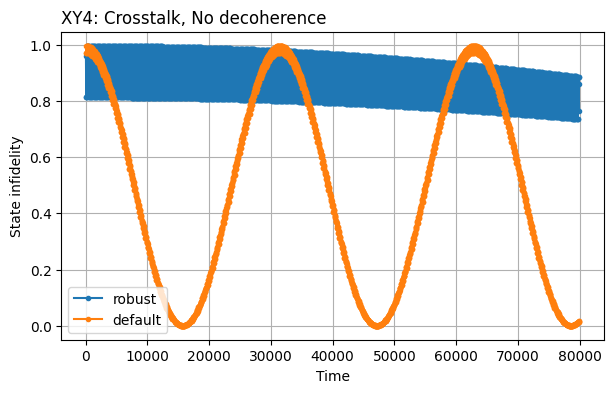

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4])
axes = axes if isinstance(axes, np.ndarray) else [axes]

y0 = ps.qiskit_ground_state(len(registers), open=False)

ax = axes[0]
ax.set_title("XY4: Crosstalk, No decoherence", loc='left')

for i, Uts_i in enumerate([Uts_0, Uts_1]):
    infids = []
    for r, t in zip(Uts_i, Uts):
        # infids.append(1 - qk.quantum_info.process_fidelity(r, t, require_cp=False, require_tp=False))
        infids.append(qk.quantum_info.state_fidelity(y0.evolve(r), y0.evolve(t), validate=False))
    ax.plot(measure_times, infids, label=labels[i], marker=".")

ax.set_xlabel("Time")
ax.legend(loc="lower left")
# ax.set_yscale("log")
ax.set_ylabel("State infidelity")
ax.grid(True)

## Decoherence

In [ ]:
y0 = ps.qiskit_identity_operator(len(registers), open=True)
# y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["robust", "default"]
schedules = [prep_robust_sched, prep_sched]

solver_rx.model.evaluation_mode = "sparse_vectorized"
prep_res_x = solver_rx.solve(
    t_span=[0.0, prep_sched.duration * dt],
    t_eval=prep_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(prep_moments, registers))
# y_target = y0.evolve(target)

for i in range(len(prep_res_x)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.process_fidelity(prep_res_x[i].y[-1], target)}"
    )

# for i in range(len(prep_res_x)):
#     print(
#         f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(prep_res_x[i].y[-1], y_target)}"
#     )

	Infidelity of robust schedule: 0.005613559380929223
	Infidelity of default schedule: 0.005645366802758733


In [ ]:
y0 = ps.qiskit_identity_operator(len(registers), open=True)
# y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["robust", "default"]
schedules = [run_robust_sched, run_sched]

solver_rx.model.evaluation_mode = "sparse_vectorized"
run_res_x = solver_rx.solve(
    t_span=[0.0, run_sched.duration * dt],
    t_eval=run_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(run_moments, registers))
# y_target = y0.evolve(target)

for i in range(len(run_res_x)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.process_fidelity(run_res_x[i].y[-1], target)}"
    )

# for i in range(len(run_res_x)):
#     print(
#         f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(run_res_x[i].y[-1], y_target)}"
#     )

	Infidelity of robust schedule: 0.02224550811096071
	Infidelity of default schedule: 0.022731074412958963


In [ ]:
Uts_0, measure_times_0 = extend(
    prep_res_x[0].y, 
    prep_times, 
    run_res_x[0].y, 
    run_times, 
    xy4_depth
)

Uts_1, measure_times_1 = extend(
    prep_res_x[1].y, 
    prep_times, 
    run_res_x[1].y, 
    run_times, 
    xy4_depth
)

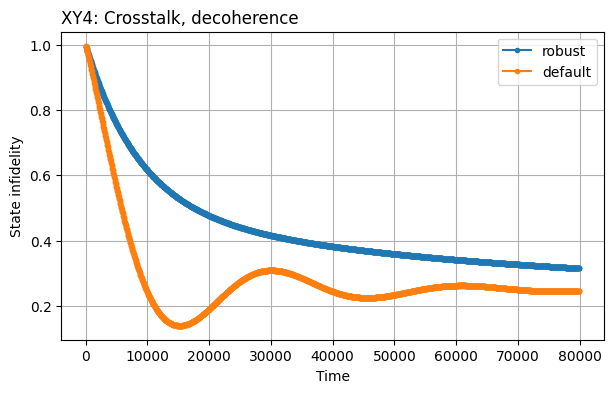

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4])
axes = axes if isinstance(axes, np.ndarray) else [axes]

y0 = ps.qiskit_ground_state(len(registers), open=True)

ax = axes[0]
ax.set_title("XY4: Crosstalk, decoherence", loc='left')

for i, Uts_i in enumerate([Uts_0, Uts_1]):
    infids = []
    for r, t in zip(Uts_i, Uts):
        # infids.append(1 - qk.quantum_info.process_fidelity(r, t, require_cp=False, require_tp=False))
        infids.append(qk.quantum_info.state_fidelity(y0.evolve(r), y0.evolve(t), validate=False))
    ax.plot(measure_times, infids, label=labels[i], marker=".")

ax.set_xlabel("Time")
ax.legend(loc="upper right")
# ax.set_yscale("log")
ax.set_ylabel("State infidelity")
ax.grid(True)

## Decoherence + Fine calibration issue

In [ ]:
y0 = ps.qiskit_identity_operator(len(registers), open=True)
# y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["robust", "default"]
schedules = [prep_robust_sched, prep_sched]

solver_rx_calibrate.model.evaluation_mode = "sparse_vectorized"
prep_res_x = solver_rx_calibrate.solve(
    t_span=[0.0, prep_sched.duration * dt],
    t_eval=prep_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(prep_moments, registers))
# y_target = y0.evolve(target)

for i in range(len(prep_res_x)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.process_fidelity(prep_res_x[i].y[-1], target)}"
    )

# for i in range(len(prep_res_x)):
#     print(
#         f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(prep_res_x[i].y[-1], y_target)}"
#     )

	Infidelity of robust schedule: 0.04494835418116283
	Infidelity of default schedule: 0.008699778544218661


In [ ]:
y0 = ps.qiskit_identity_operator(len(registers), open=True)
# y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["robust", "default"]
schedules = [run_robust_sched, run_sched]

solver_rx_calibrate.model.evaluation_mode = "sparse_vectorized"
run_res_x = solver_rx_calibrate.solve(
    t_span=[0.0, run_sched.duration * dt],
    t_eval=run_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(run_moments, registers))
# y_target = y0.evolve(target)

for i in range(len(run_res_x)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.process_fidelity(run_res_x[i].y[-1], target)}"
    )

# for i in range(len(run_res_x)):
#     print(
#         f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(run_res_x[i].y[-1], y_target)}"
#     )

	Infidelity of robust schedule: 0.02224637958064979
	Infidelity of default schedule: 0.02271774843804797


In [ ]:
Uts_0, measure_times_0 = extend(
    prep_res_x[0].y, 
    prep_times, 
    run_res_x[0].y, 
    run_times, 
    xy4_depth
)

Uts_1, measure_times_1 = extend(
    prep_res_x[1].y, 
    prep_times, 
    run_res_x[1].y, 
    run_times, 
    xy4_depth
)

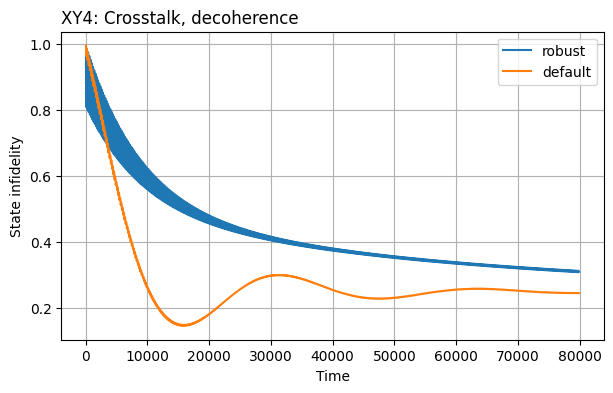

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4])
axes = axes if isinstance(axes, np.ndarray) else [axes]

y0 = ps.qiskit_ground_state(len(registers), open=True)

ax = axes[0]
ax.set_title("XY4: Crosstalk, decoherence", loc='left')

for i, Uts_i in enumerate([Uts_0, Uts_1]):
    infids = []
    for r, t in zip(Uts_i, Uts):
        # infids.append(1 - qk.quantum_info.process_fidelity(r, t, require_cp=False, require_tp=False))
        infids.append(qk.quantum_info.state_fidelity(y0.evolve(r), y0.evolve(t), validate=False))
    ax.plot(measure_times, infids, label=labels[i], marker=".")

ax.set_xlabel("Time")
ax.legend(loc="upper right")
# ax.set_yscale("log")
ax.set_ylabel("State infidelity")
ax.grid(True)